In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
BASE_DIR = Path().cwd().parent
ass_path = BASE_DIR/'data'/'raw'/'assessments.csv'
cou_path = BASE_DIR/'data'/'raw'/'courses.csv'
OUT_path = BASE_DIR/'outputs'

# Load, Clean & Merge

In [3]:
df = pd.read_csv(ass_path)

display(df.head())

print("\nInfo:")
print(df.info())

print("\nShape:",df.shape)

,assessment_id,month,course_id,batch,score,attendance_pct
0,1,Jan,C1,Morning,72,90
1,2,Jan,C2,Evening,45,70
2,3,Jan,C3,Morning,65,85
3,4,Jan,C4,Weekend,38,60
4,5,Feb,C1,Evening,80,95



Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   assessment_id   13 non-null     int64 
 1   month           13 non-null     object
 2   course_id       13 non-null     object
 3   batch           13 non-null     object
 4   score           13 non-null     int64 
 5   attendance_pct  13 non-null     int64 
dtypes: int64(3), object(3)
memory usage: 756.0+ bytes
None

Shape: (13, 6)


In [4]:
lookup_df = pd.read_csv(cou_path)

display(lookup_df.head())

print("\nInfo:")
print(lookup_df.info())

print("\nShape:",lookup_df.shape)

,course_id,course,department
0,C1,Excel,Business
1,C2,PowerBI,Business
2,C3,SQL,Technology
3,C4,Python,Technology



Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   course_id   4 non-null      object
 1   course      4 non-null      object
 2   department  4 non-null      object
dtypes: object(3)
memory usage: 228.0+ bytes
None

Shape: (4, 3)


In [5]:
# check Datatype
print("Data type of Score:",df["score"].dtype)
print("Data type of Score:",df["attendance_pct"].dtype)

Data type of Score: int64
Data type of Score: int64


In [6]:
# check Duplicate
print("Before Duplicate count:",df.duplicated().sum())

Before Duplicate count: 1


In [7]:
# remove Duplicate
df=df.drop_duplicates().copy()

In [8]:
# after remove duplicate check
print("After Duplicate count:",df.duplicated().sum())

After Duplicate count: 0


In [9]:
# Mearge Dataset on course_id(left join)
merge_df = df.merge(lookup_df,on="course_id",how="left",validate="many_to_one")

display(merge_df.head())

print("\nInfo:")
print(merge_df.info())

print("\nShape:",merge_df.shape)

,assessment_id,month,course_id,batch,score,attendance_pct,course,department
0,1,Jan,C1,Morning,72,90,Excel,Business
1,2,Jan,C2,Evening,45,70,PowerBI,Business
2,3,Jan,C3,Morning,65,85,SQL,Technology
3,4,Jan,C4,Weekend,38,60,Python,Technology
4,5,Feb,C1,Evening,80,95,Excel,Business



Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   assessment_id   12 non-null     int64 
 1   month           12 non-null     object
 2   course_id       12 non-null     object
 3   batch           12 non-null     object
 4   score           12 non-null     int64 
 5   attendance_pct  12 non-null     int64 
 6   course          12 non-null     object
 7   department      12 non-null     object
dtypes: int64(3), object(5)
memory usage: 900.0+ bytes
None

Shape: (12, 8)


In [10]:
# assert merge_Df
assert merge_df["assessment_id"].count()==12
assert merge_df["course"].isna().sum()==0

# Derived Field & Department Analysis

In [11]:
# create pass_flag column in merge df
merge_df["pass_flag"]=(df["score"]>=50).astype(int)

display(merge_df[["assessment_id","pass_flag"]].head())

,assessment_id,pass_flag
0,1,1
1,2,0
2,3,1
3,4,0
4,5,1


In [13]:
# create summary or department
department_summary = merge_df.groupby("department",as_index=False).agg(
    assessments=("assessment_id","count"),
    pass_count =  ("pass_flag","sum")
)

department_summary["pass_rate"] = department_summary["pass_count"]/department_summary["assessments"]*100

display(department_summary)

,department,assessments,pass_count,pass_rate
0,Business,6,5,83.333333
1,Technology,6,3,50.000000


In [14]:
course_summary = merge_df.groupby("course",as_index=False).agg(
    assessments=("assessment_id","count"),
    pass_count =  ("pass_flag","sum")
)
course_summary["pass_rate"] = course_summary["pass_count"]/course_summary["assessments"]*100

top_course = course_summary.sort_values(by="pass_rate").head(1)

In [15]:
print("Lowest Pass rate Course name:",top_course["course"].values[0])
print("Lowest Pass rate Course assessments:",top_course["assessments"].values[0])
print("Lowest Pass rate Course pass_count:",top_course["pass_count"].values[0])
print("Lowest Pass rate Course pass_rate:",top_course["pass_rate"].values[0].round(2))

Lowest Pass rate Course name: Python
Lowest Pass rate Course assessments: 3
Lowest Pass rate Course pass_count: 1
Lowest Pass rate Course pass_rate: 33.33


# Chart & Exports

In [16]:
merge_df["month"].unique()

array(['Jan', 'Feb', 'Mar'], dtype=object)

In [20]:
monthly_sum = merge_df.groupby("month")["score"].mean().reindex(["Jan","Feb","Mar"])

monthly_sum

month
Jan    55.00
Feb    62.75
Mar    66.75
Name: score, dtype: float64

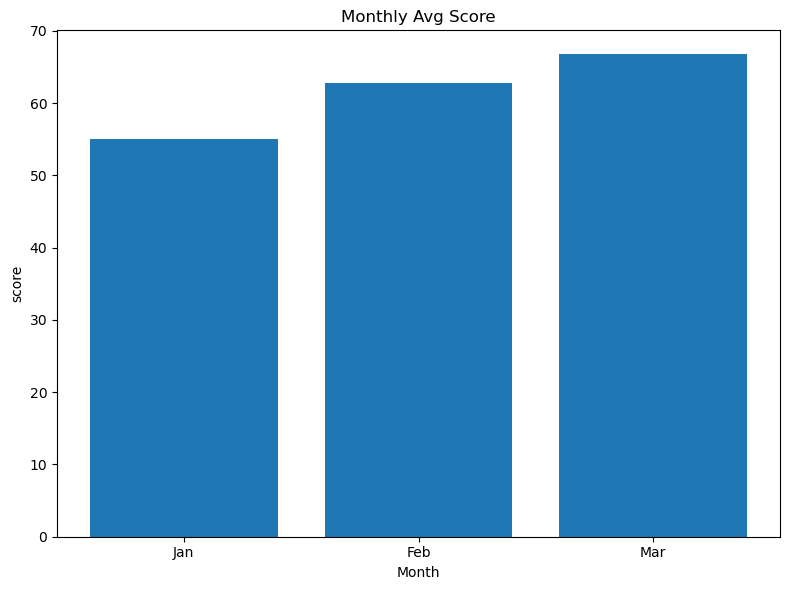

In [22]:
plt.figure(figsize=(8,6))
plt.bar(monthly_sum.index,monthly_sum.values)
plt.title("Monthly Avg Score")
plt.xlabel("Month")
plt.ylabel("score")
plt.tight_layout()
plt.savefig(OUT_path/"python_chart.png")
plt.show()

In [24]:
# merge_df (mean export clean dataset)
# and save summary 
merge_df.to_csv(OUT_path/"clean_data.csv",index=False)
department_summary.to_csv(OUT_path/"department_summary.csv",index=False)
course_summary.to_csv(OUT_path/"course_summary.csv",index=False)